### code to translate German to English and vice versa with deepL

In [1]:
import pandas as pd
from pprint import pprint
import os
import ast
import deepl
import json
import requests
import matplotlib.pyplot as plt

In [2]:
# get connection to deepl api
deepl_key = open("/Users/sofiaromero/Documents/DeepL.txt").read()
deepl_client = deepl.DeepLClient(deepl_key)

In [3]:
# api functions 

def generate_glossaries(dict_path_l, s_lang, t_lang, auth_key):
    url = "https://api-free.deepl.com/v3/glossaries"
    header= {
        "Authorization": f"DeepL-Auth-Key {auth_key}",
        "User-Agent": "YourApp/1.2.3",
        "Content-Type": "application/json"
    }    
    glossaries = []
    for i,d in enumerate(dict_path_l):
        payload = {
            "name": f"glossary{i}",
            "dictionaries": [{
                # TODO: get languages from file name
                "source_lang": s_lang,
                "target_lang": t_lang,
                "entries": open(d,"r").read(),
                "entries_format": "csv"}
            ]}
        resp = requests.post(url, headers=header, json=payload)
        print(resp.status_code, resp.json())
        glossaries.append(resp.json())
    return glossaries


def get_glossary_ids(auth_key):
    url = "https://api-free.deepl.com/v3/glossaries"
    headers = {
        "Authorization": f"DeepL-Auth-Key {auth_key}",
        "User-Agent": "YourApp/1.2.3",
    }
    resp = requests.get(url, headers=headers, timeout=30)
    print(resp.status_code)
    return [x.get("glossary_id") for x in resp.json()["glossaries"]]


def transalate_to(text_l, s_lang, t_lang, glossary_id):
    res = []
    for text in text_l:
        if glossary_id:
            res.append(deepl_client.translate_text(text, target_lang=t_lang, source_lang=s_lang, glossary=glossary_id).text)
        else: 
            res.append(deepl_client.translate_text(text, target_lang=t_lang, source_lang=s_lang).text)
    return res


In [4]:
#generate_glossaries(["config_files/ger_to_eng.csv"], "DE", "EN", deepl_key)
# get all current glossaries
glossary_ids = get_glossary_ids(deepl_key)

200


In [5]:
# translate ki terms as test
'''
test_terms = list(ast.literal_eval(open("config_files/ger_anthroscore_KI_terms.txt").read()).values())
print(test_terms)
translations = transalate_to(test_terms, "DE", "EN-GB", glossary_ids[0])
print(translations)
'''

'\ntest_terms = list(ast.literal_eval(open("config_files/ger_anthroscore_KI_terms.txt").read()).values())\nprint(test_terms)\ntranslations = transalate_to(test_terms, "DE", "EN-GB", glossary_ids[0])\nprint(translations)\n'

In [5]:
# write text (from file) and its transaltion to df and save to csv and json file
def tranlate_to_df(txts_json, file_to):
    # load json as dict
    with open(txts_json, "r") as f:
        txts = json.load(f)

    res_df = pd.DataFrame([(key, var) for (key, L) in txts.items() for var in L], columns=['id', 'text']).drop_duplicates(subset=['text']).reset_index(drop=True)
    #fill df with traslations
    res_df['translation'] = transalate_to(res_df['text'].tolist(), "DE", "EN-GB", glossary_ids[0]) # TODO: changing source and target langs dependeing on input
    #save to file 
    res_df.to_csv(f"{file_to}.csv", index=False)
    res_df.to_json(f"{file_to}.json", orient="records")
    return res_df


### Translate KI_sentences to English

In [ ]:
#tranlate_to_df("generated_data/KI_sentences.json", "generated_data/KI_sentences_translated")

In [ ]:
# input to anthroscore
# get AI-related words, sorted according to 'Häufigkeitsklassen' and from AnthroScore
# https://corpora.uni-leipzig.de/de/res?corpusId=deu_news_2024&word=KI
ki_terms = list(ast.literal_eval(open("config_files/ger_anthroscore_KI_terms.txt").read()).values())
ki_terms += ['KI','Künstliche Intelligenz', 'ChatGPT', 'AI', 'Copilot', 'Gemini', 'Chatbot','LLM', 'Chat-GPT',
            'Sprachmodell', 'KI-Modell', 'KI-System', 'KI-Tool', 'Artificial Intelligence', 'KI-Anwendung']
ai_terms = transalate_to(ki_terms, "DE", "EN-GB", glossary_ids[0])

In [8]:
with open(f"config_files/ai_terms.txt", "w") as f:
        f.writelines([" "+x for x in ai_terms])
        f.close()

with open(f"config_files/ki_terms.txt", "w") as f:
        f.writelines([" "+x for x in ki_terms])
        f.close()

NameError: name 'ai_terms' is not defined

In [4]:
# anthroscore for translated (english) sentences, without "palm"
ai_terms = open(f"config_files/ai_terms.txt", "r").read()
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/KI_sentences_eng_scores.csv --text_id_name id '''
terminal_input

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities lms llama transformer Language models Language model gpt plms pre-trained language models gpt-2 xlnet large language models llms gpt-3 Foundation model gpt-neo gpt-j chatgpt gpt-4 AI Artificial intelligence ChatGPT AI Copilot Gemini Chatbot LLM Chat GPT Language model AI model AI system AI tool Artificial Intelligence AI application --output_file generated_data/KI_sentences_eng_scores.csv --text_id_name id '

In [5]:
# anthroscore for german sentences, without "palm"
ki_terms = open(f"config_files/ki_terms.txt", "r").read()
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/KI_sentences_ger_scores.csv --text_id_name id '''
terminal_input_ger

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities lms llama Transformer Sprachmodelle Sprachmodell gpt plms vortrainierte Sprachmodelle gpt-2 xlnet große Sprachmodelle llms gpt-3 Stiftungsmodell gpt-neo gpt-j chatgpt gpt-4 KI Künstliche Intelligenz ChatGPT AI Copilot Gemini Chatbot LLM Chat-GPT Sprachmodell KI-Modell KI-System KI-Tool Artificial Intelligence KI-Anwendung --output_file generated_data/KI_sentences_ger_scores.csv --text_id_name id '

In [14]:
# anthroscore for translated (english) sentences, with "palm"
ai_terms = open(f"config_files/ai_terms.txt", "r").read()
terminal_input = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities {ai_terms} --output_file generated_data/KI_sentences_eng_scores_palm.csv --text_id_name id '''
terminal_input

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name translation --entities palm lms llama transformer Language models Language model gpt plms pre-trained language models gpt-2 xlnet large language models llms gpt-3 Foundation model gpt-neo gpt-j chatgpt gpt-4 AI Artificial intelligence ChatGPT AI Copilot Gemini Chatbot LLM Chat GPT Language model AI model AI system AI tool Artificial Intelligence AI application --output_file generated_data/KI_sentences_eng_scores_palm.csv --text_id_name id '

In [15]:
# anthroscore for german sentences, with "palm"
ki_terms = open(f"config_files/ki_terms.txt", "r").read()
terminal_input_ger = f'''python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities {ki_terms} --output_file generated_data/KI_sentences_ger_scores_palm.csv --text_id_name id '''
terminal_input_ger

'python3 anthroscore/src/get_anthroscore.py --input_file generated_data/KI_sentences_translated.csv --text_column_name text --entities palm lms llama Transformer Sprachmodelle Sprachmodell gpt plms vortrainierte Sprachmodelle gpt-2 xlnet große Sprachmodelle llms gpt-3 Stiftungsmodell gpt-neo gpt-j chatgpt gpt-4 KI Künstliche Intelligenz ChatGPT AI Copilot Gemini Chatbot LLM Chat-GPT Sprachmodell KI-Modell KI-System KI-Tool Artificial Intelligence KI-Anwendung --output_file generated_data/KI_sentences_ger_scores_palm.csv --text_id_name id '

#### AntroScore Results

In [16]:
#delete duplicate sentences
text_scores = pd.read_csv(f"generated_data/KI_sentences_translated_sentence_scores_ger.csv")#.drop_duplicates(subset=['sentence']).reset_index(drop=True)
translated_scores =  pd.read_csv(f"generated_data/KI_sentences_translated_sentence_scores_eng.csv")#.drop_duplicates(subset=['sentence']).reset_index(drop=True)

ger: count    1195.000000
mean        0.747938
std         1.798241
min        -6.121003
25%        -0.203957
50%         1.116554
75%         1.568181
max         7.870180
Name: anthroscore, dtype: float64
-------------------
eng: count    1617.000000
mean       -0.773252
std         2.522761
min        -8.127385
25%        -2.610020
50%        -0.775624
75%         0.913109
max         9.124494
Name: anthroscore, dtype: float64


{'whiskers': [<matplotlib.lines.Line2D at 0x1174f1d60>,
 'caps': [<matplotlib.lines.Line2D at 0x1174f2360>,
 'boxes': [<matplotlib.lines.Line2D at 0x1174f1a30>],
 'medians': [<matplotlib.lines.Line2D at 0x1174f2930>],
 'fliers': [<matplotlib.lines.Line2D at 0x1174f2ba0>],
 'means': []}

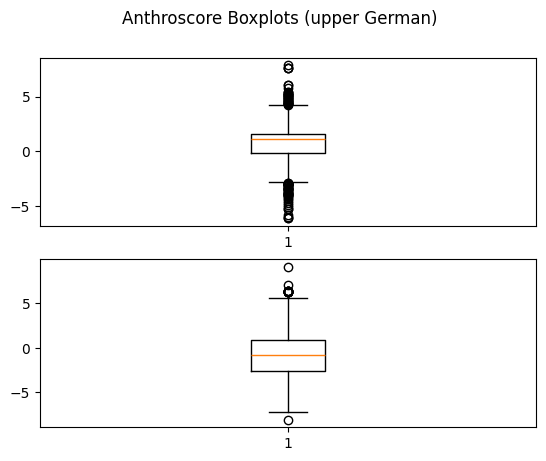

In [21]:
# plot score distributions, compare languages
ger_results = text_scores["anthroscore"]
eng_results = translated_scores["anthroscore"]
max_len = max([len(eng_results), len(ger_results)])
print("ger:",ger_results.describe())
print("-------------------")
print("eng:",eng_results.describe())

fig, axs = plt.subplots(2)
fig.suptitle('Anthroscore Boxplots (upper German)')
axs[0].boxplot(ger_results)
axs[1].boxplot(eng_results)

In [19]:
#print(text_scores.head())
ger_grouped = text_scores.groupby(["original_term"])
ger_mean = ger_grouped["anthroscore"].mean()

eng_grouped = translated_scores.groupby(["original_term"])
eng_mean = eng_grouped["anthroscore"].mean()

print("ger:",ger_mean)
print("-------------------")
print("eng:",eng_mean)


ger: original_term
AI                 0.533996
Artificial         0.495856
ChatGPT            1.039946
Chatbot            1.121539
Copilot            0.920569
Gemini             1.017331
Intelligence       0.959324
Intelligenz        0.915234
KI                 0.726169
Künstliche         0.977819
Sprachmodell       0.444906
Sprachmodelle     -0.346161
Stiftungsmodell    0.332253
Transformer        0.967429
chatgpt            1.039946
gpt               -0.917521
große              0.748269
llama              1.400988
Name: anthroscore, dtype: float64
-------------------
eng: original_term
AI              0.096338
Artificial     -1.902706
Chat           -3.971190
ChatGPT        -2.544142
Chatbot        -1.298129
Copilot         3.975721
Foundation     -2.767267
GPT            -1.755609
Gemini         -1.122534
Intelligence   -1.942242
Language       -0.973121
application    -4.164199
chatgpt        -2.544142
gpt            -1.755609
intelligence   -1.942242
language       -0.973121
larg

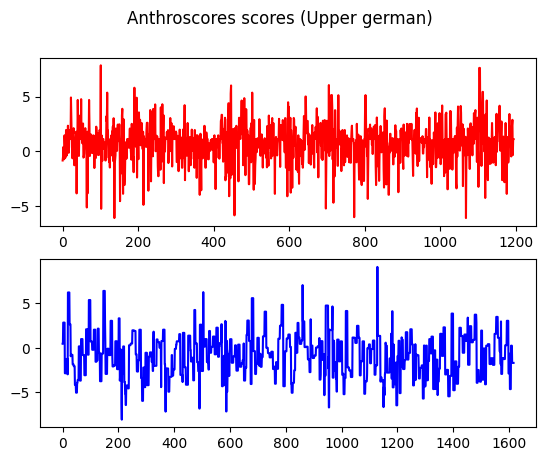

In [20]:
fig, axs = plt.subplots(2)
fig.suptitle('Anthroscores scores (Upper german)')
axs[0].plot(ger_results, color = 'red')
axs[1].plot(eng_results, color = 'blue')